In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from solvers.explicit_adams import solveExplicitAdams
from solvers.explicit_runge_kutta import solveExplicitRungeKutta
from solvers.implicit_runge_kutta import solveImplicitRungeKutta
from solvers.gear import solveGear

# Проверка порядка для обычного уравнения

``` y' = -y ```

``` y = A e^{-t} ```

``` y(0) = 1 ```

In [3]:
def y_theory(x):
    return np.exp(-np.asarray(x))

y_0 = np.array([1])

t_start = 0
t_end = 5

def f(t, y):
    return -y

t_theory_vals = np.linspace(t_start, t_end, 1000)
y_theory_vals = y_theory(t_theory_vals)

Средние наблюдаемые порядки сходимости
РК1: 1.0316
РК2: 2.0541
РК3: 3.0561
РК4: 4.0584


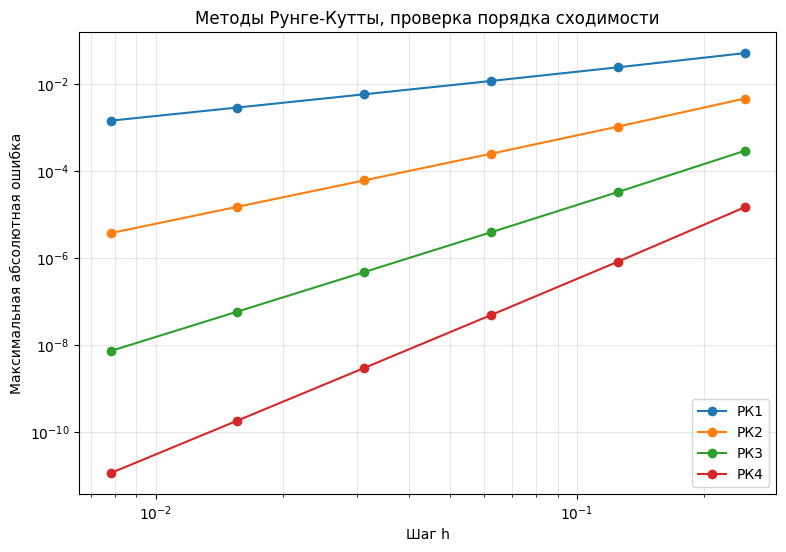

In [4]:
def calculate_error(solver, h, s):
    t_real, y_real = solver(f, y_0, t_start, t_end, h, s)
    y_theory_vals = y_theory(t_real)

    return np.max(np.abs(y_theory_vals - np.asarray(y_real)[:, 0]))

h_values = 1 / (2 ** np.arange(2, 8))

def plot_convergence(solver, label, title):
    plt.figure(figsize=(9, 6))
    print("Средние наблюдаемые порядки сходимости")
    for s in range(1, 5):
        errors = np.array([calculate_error(solver, h, s) for h in h_values])
        plt.loglog(h_values, errors, marker="o", label=f"{label}{s}")
        orders = np.log(errors[:-1] / errors[1:]) / np.log(h_values[:-1] / h_values[1:])
        print(f"{label}{s}: {np.mean(orders):.4f}")

    plt.xlabel("Шаг h")
    plt.ylabel("Максимальная абсолютная ошибка")
    plt.legend()
    plt.grid(True, which="both", alpha=0.3)
    plt.title(title)
    plt.show()

plot_convergence(solveExplicitRungeKutta, "РК", "Методы Рунге-Кутты, проверка порядка сходимости")

Средние наблюдаемые порядки сходимости
АБ1: 1.0316
АБ2: 1.9709
АБ3: 2.9320
АБ4: 3.9179


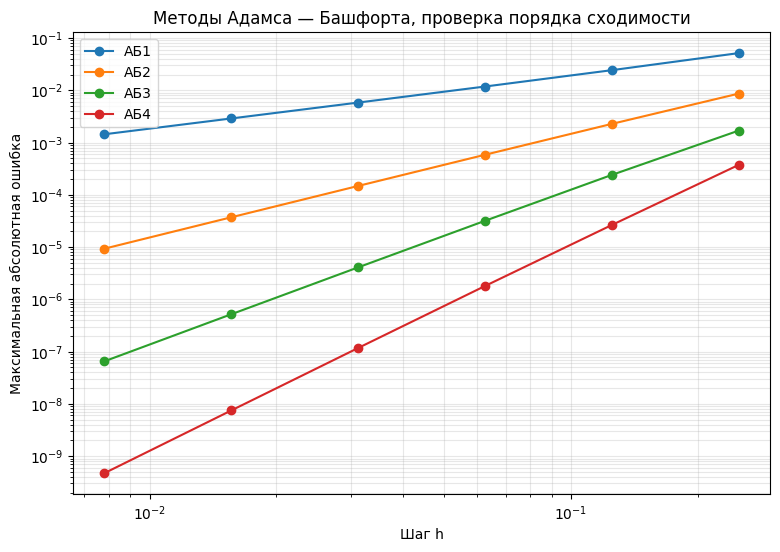

In [5]:
def adams_with_step(f, y0, t0, t_end, h, s):
    n_steps = round((t_end - t0) / h)
    return solveExplicitAdams(f, y0, t0, t_end, n_steps, s)

plot_convergence(adams_with_step, "АБ", "Методы Адамса — Башфорта, проверка порядка сходимости")

Средние наблюдаемые порядки сходимости
НРК1: 0.9729
НРК2: 2.0020
НРК3: 2.9828
НРК4: 4.0010


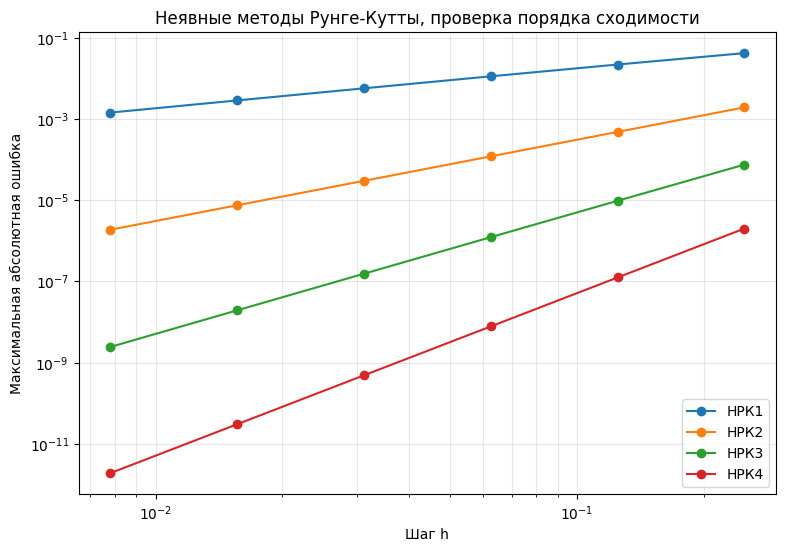

In [6]:
def dfdy(t, y):
    return -np.eye(len(y))

def implicit_rk_with_step(f, y0, t0, t_end, h, order):
    return solveImplicitRungeKutta(f, dfdy, y0, t0, t_end, h, order)

plot_convergence(implicit_rk_with_step, "НРК", "Неявные методы Рунге-Кутты, проверка порядка сходимости")

Средние наблюдаемые порядки сходимости
BDF1: 0.9729
BDF2: 1.9419
BDF3: 2.9139
BDF4: 3.8816


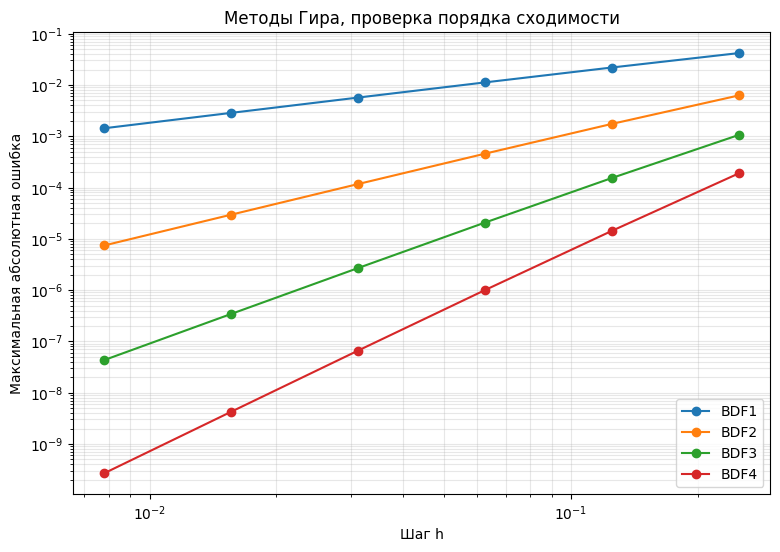

In [7]:
def gear_with_step(f, y0, t0, t_end, h, order):
    return solveGear(f, dfdy, y0, t0, t_end, h, order)

plot_convergence(gear_with_step, "BDF", "Методы Гира, проверка порядка сходимости")